# 05 · Universo de instrumentos (bloque 5)

Este notebook recorre el **universo** del Tema 1 (`config/universo.yaml`, validado por
`ingesta.mercados_series.universo`): los 42 ETF de la propuesta, los baselines, ~50 ETF de ampliación,
los equivalentes **UCITS** que un minorista de la UE sí puede comprar, índices, volatilidad, divisas,
futuros de contexto y cripto. Después, la composición **point-in-time** del S&P 500 (fja05680/sp500) y las
fotos actuales de otros índices.

Solo metadatos: fechas, recuentos y pertenencias. Ningún precio.

In [1]:
%matplotlib inline
import json
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.mercados_series import universo as U
from ingesta.mercados_series.fuentes import constituyentes as C

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 80, 'axes.spines.top': False, 'axes.spines.right': False})
TABLAS = resultados_dir('mercados_series') / 'tablas'
UNI = U.cargar_universo()
DF = U.tabla_universo(UNI)
JT = pd.read_csv(TABLAS / U.FICHERO_JUSTETF)
YH = pd.read_csv(TABLAS / U.FICHERO_YAHOO) if (TABLAS / U.FICHERO_YAHOO).exists() else None
print(f"{len(DF)} instrumentos; {DF['invertible_minorista_ue'].sum()} invertibles por un minorista de la UE")
print(f"justETF: {JT['lanzamiento_justetf'].notna().sum()} de {len(JT)} UCITS con fecha de lanzamiento")

202 instrumentos; 52 invertibles por un minorista de la UE
justETF: 47 de 47 UCITS con fecha de lanzamiento


## 1. Universo por clase, capa y región

La mayoría son ETF; las capas separan lo **estratégico** (núcleo de la cartera), lo **táctico**
(rotación por régimen), el **contexto** (señales no invertibles: índices, volatilidad, futuros, FX) y los
**baselines**.

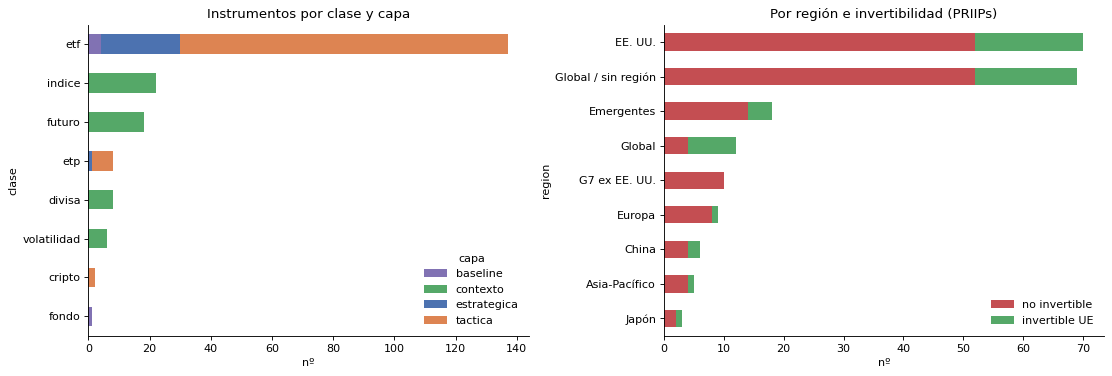

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
t = pd.crosstab(DF['clase'], DF['capa'])
t = t.loc[t.sum(axis=1).sort_values().index]
t.plot.barh(stacked=True, ax=axes[0], color=['#8172B3', '#55A868', '#4C72B0', '#DD8452'][:t.shape[1]])
axes[0].set_title('Instrumentos por clase y capa'); axes[0].set_xlabel('nº'); axes[0].legend(title='capa', frameon=False)
r = pd.crosstab(DF['region'], DF['invertible_minorista_ue']).rename(columns={True: 'invertible UE', False: 'no invertible'})
r = r.loc[r.sum(axis=1).sort_values().index]
r.plot.barh(stacked=True, ax=axes[1], color=['#C44E52', '#55A868'])
axes[1].set_title('Por región e invertibilidad (PRIIPs)'); axes[1].set_xlabel('nº'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Fechas de inicio

`inicio_esperado` es la primera cotización documentada; en los UCITS, la fecha de lanzamiento **medida en
justETF**. Con `tablas/universo_yahoo.csv` se compara con el primer día que Yahoo tiene de verdad: los
puntos por encima de la diagonal son historia que Yahoo no guarda (p. ej. EURO STOXX 50 antes de 2007) y
los de debajo, historia anterior al lanzamiento declarado (índices enlazados, OTC).

Tickers sin datos en Yahoo: ['^V2TX']
Más de 30 días de diferencia: ['yf:ETHE', 'yf:CSPX.L', 'yf:CNDX.L', 'yf:ZPRR.DE', 'yf:FXC.L', 'yf:XCS6.DE', 'yf:IBZL.L', 'yf:CPXJ.L', 'yf:XDEW.DE', 'yf:IBTM.L', 'yf:IBTS.L', 'yf:ITPS.L', 'yf:LQDE.L', 'yf:IUAA.L', 'yf:CRUD.L', 'yf:AIGA.L', 'yf:COPA.L', 'yf:IUSP.L', 'yf:IWDP.L', 'yf:^KS11', 'yf:^VIX3M', 'coinbase:BTC-USD', 'coinbase:ETH-USD']


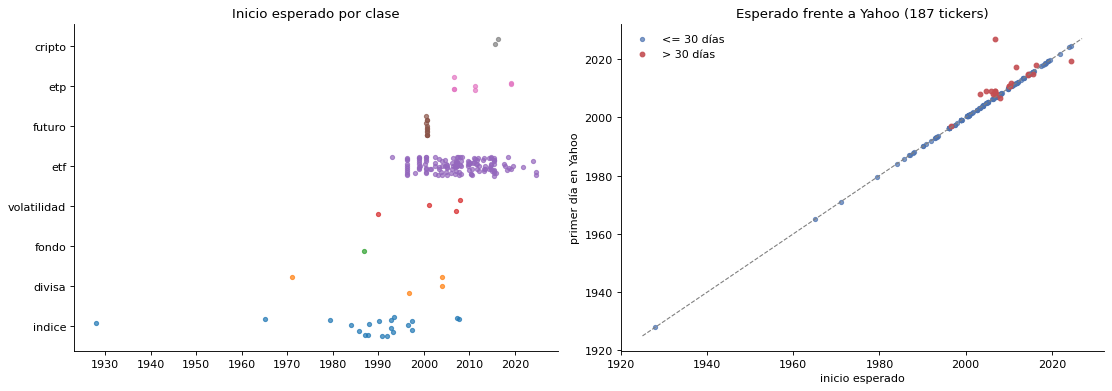

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
orden = DF.groupby('clase')['inicio_esperado'].min().sort_values().index
for k, c in enumerate(orden):
    f = DF.loc[DF['clase'] == c, 'inicio_esperado'].dropna()
    axes[0].scatter(f, np.full(len(f), k) + np.random.default_rng(k).uniform(-.25, .25, len(f)), s=14, alpha=.7)
axes[0].set_yticks(range(len(orden)), orden); axes[0].set_title('Inicio esperado por clase')
axes[0].xaxis.set_major_locator(mdates.YearLocator(10)); axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
if YH is not None:
    m = DF.merge(YH, on='id', how='inner').dropna(subset=['inicio_esperado', 'primer_dia'])
    m['primer_dia'] = pd.to_datetime(m['primer_dia'])
    lejos = (m['primer_dia'] - m['inicio_esperado']).dt.days.abs() > 30
    axes[1].scatter(m.loc[~lejos, 'inicio_esperado'], m.loc[~lejos, 'primer_dia'], s=14, alpha=.7, color='#4C72B0', label='<= 30 días')
    axes[1].scatter(m.loc[lejos, 'inicio_esperado'], m.loc[lejos, 'primer_dia'], s=18, alpha=.9, color='#C44E52', label='> 30 días')
    lim = [pd.Timestamp('1925-01-01'), pd.Timestamp('2027-01-01')]
    axes[1].plot(lim, lim, color='grey', lw=1, ls='--'); axes[1].set_xlabel('inicio esperado'); axes[1].set_ylabel('primer día en Yahoo')
    axes[1].set_title(f'Esperado frente a Yahoo ({len(m)} tickers)'); axes[1].legend(frameon=False)
    print('Tickers sin datos en Yahoo:', YH.loc[YH['primer_dia'].isna(), 'ticker_yahoo'].tolist())
    print('Más de 30 días de diferencia:', m.loc[lejos, 'id'].tolist())
else:
    axes[1].axis('off')
plt.tight_layout(); plt.show()

In [4]:
if YH is not None:
    m = DF.merge(YH, on='id', how='inner').dropna(subset=['divisa_yahoo'])
    dif = m[m['divisa'] != m['divisa_yahoo']]
    print('Divisa declarada distinta de la de Yahoo:', list(zip(dif['id'], dif['divisa'], dif['divisa_yahoo'])))

Divisa declarada distinta de la de Yahoo: []


## 3. Empalmes UCITS

Un UCITS suele ser más joven que su equivalente de EE. UU. La historia se empalma: **proxy previo** (ETF de
EE. UU., índice o cripto al contado) hasta el lanzamiento del UCITS y el UCITS después. La barra gris es el
tramo que depende del proxy.

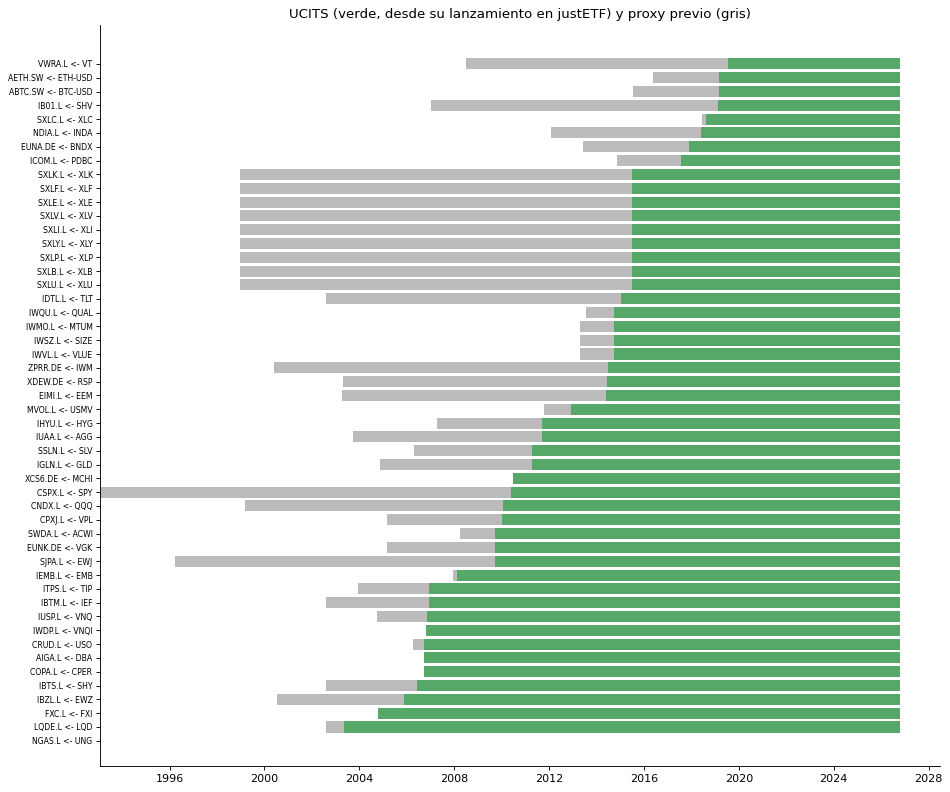

Años cubiertos solo por el proxy: mediana 4.5, máximo 17.3


In [5]:
uc = DF[(DF['grupo'] == 'ucits') & DF['proxy_previo'].notna()].copy()
ini = DF.set_index('id')['inicio_esperado']
uc['inicio_proxy'] = uc['proxy_previo'].map(ini)
uc = uc.sort_values('inicio_esperado', na_position='first').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 10))
hoy = pd.Timestamp.today().normalize()
for k, r in uc.iterrows():
    if pd.notna(r['inicio_proxy']) and pd.notna(r['inicio_esperado']):
        ax.barh(k, mdates.date2num(r['inicio_esperado']) - mdates.date2num(r['inicio_proxy']), left=mdates.date2num(r['inicio_proxy']), color='#BBBBBB')
    if pd.notna(r['inicio_esperado']):
        ax.barh(k, mdates.date2num(hoy) - mdates.date2num(r['inicio_esperado']), left=mdates.date2num(r['inicio_esperado']), color='#55A868')
ax.set_yticks(range(len(uc)), [f"{a.split(':')[1]} <- {b.split(':')[1]}" for a, b in zip(uc['id'], uc['proxy_previo'])], fontsize=7)
ax.xaxis_date(); ax.set_title('UCITS (verde, desde su lanzamiento en justETF) y proxy previo (gris)')
plt.tight_layout(); plt.show()
anos = (uc['inicio_esperado'] - uc['inicio_proxy']).dt.days / 365.25
print(f"Años cubiertos solo por el proxy: mediana {anos.median():.1f}, máximo {anos.max():.1f}")

## 4. Invertibilidad (PRIIPs)

Los ETF domiciliados en EE. UU. no publican KID PRIIPs: un minorista de la UE no puede comprarlos. Se usan
como señal y para la historia; la cartera se implementa con el equivalente UCITS (o ETC/ETP con KID).
Los fondos indexados quedan fuera de la optimización (motivo en `fondos_por_que_no_entran`).

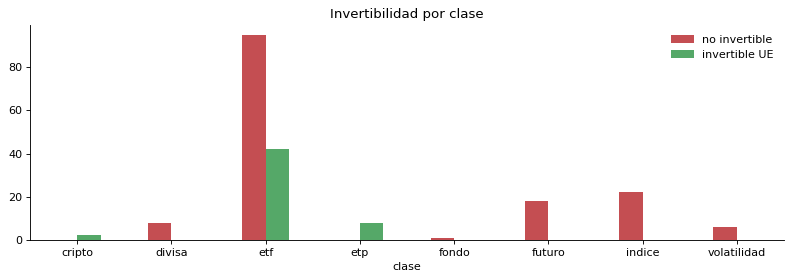

Los fondos de inversión indexados (Vanguard, iShares, Fidelity, Amundi...) no entran en la optimización: (1) solo publican un valor liquidativo diario calculado después del cierre y difundido horas más tarde (visible en t+1), sin precio intradía ni spread observable; (2) las órdenes se ejecutan a un NAV desconocido en el momento de decidir (forward pricing), lo que rompe la regla de decidir a las 16:30 NY con información visible; (3) su historia en Yahoo es corta, incompleta o inexistente para las clases en EUR, y no hay series de NAV point-in-time gratuitas; (4) replican los mismos índices que los ETF UCITS del universo, que sí cotizan y tienen coste observable (DEGIRO/IBKR). Se anotan como 'fondo_indexado_equivalente' a título informativo (alternativa de implementación para el usuario final) y VBMFX solo como proxy previo de AGG.


In [6]:
t = pd.crosstab(DF['clase'], DF['invertible_minorista_ue'])
ax = t.plot.bar(figsize=(10, 3.6), color=['#C44E52', '#55A868'], rot=0)
ax.legend(['no invertible', 'invertible UE'], frameon=False); ax.set_title('Invertibilidad por clase'); plt.tight_layout(); plt.show()
print(UNI['fondos_por_que_no_entran'])

## 5. S&P 500 point-in-time

Tramos de pertenencia reconstruidos de las instantáneas de fja05680/sp500 (desde 1996). Un ticker con
varios tramos es una reentrada **o** un ticker reutilizado por otra empresa: sin CIK/PERMNO no se distingue.

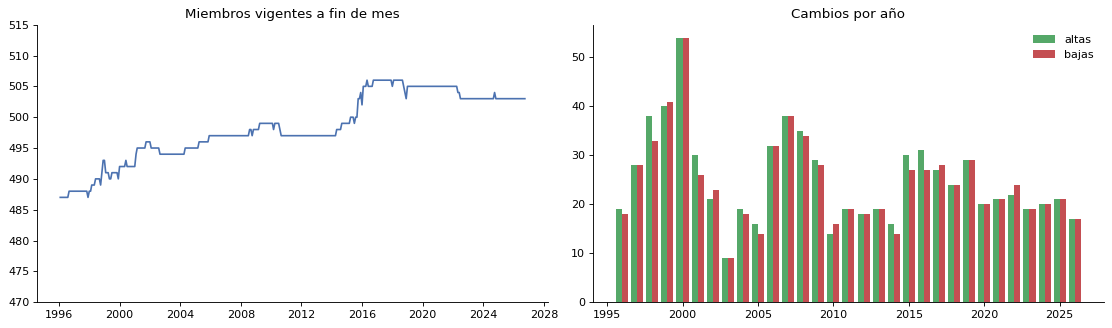

De los miembros a 2000-06-30 siguen hoy: 39%
De los miembros a 2008-06-30 siguen hoy: 50%
De los miembros a 2015-06-30 siguen hoy: 63%
Tickers con varios tramos: 52 de 1209


In [7]:
SP = pd.read_parquet(corpus_dir('mercados_series') / 'constituyentes' / 'sp500.parquet')
fechas = pd.date_range('1996-01-31', pd.Timestamp.today(), freq='ME')
n = [len(C.miembros_en(SP, f)) for f in fechas]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(fechas, n, color='#4C72B0'); axes[0].set_ylim(470, 515); axes[0].set_title('Miembros vigentes a fin de mes')
altas = SP.loc[SP['alta'] > SP['alta'].min(), 'alta'].dt.year.value_counts().sort_index()
bajas = SP['baja'].dropna().dt.year.value_counts().sort_index()
axes[1].bar(altas.index - .2, altas.values, width=.4, label='altas', color='#55A868')
axes[1].bar(bajas.index + .2, bajas.values, width=.4, label='bajas', color='#C44E52')
axes[1].set_title('Cambios por año'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
hoy = set(C.miembros_en(SP, pd.Timestamp.today()))
for anio in (2000, 2008, 2015):
    m = set(C.miembros_en(SP, f'{anio}-06-30'))
    print(f"De los miembros a {anio}-06-30 siguen hoy: {len(m & hoy) / len(m):.0%}")
print(f"Tickers con varios tramos: {(SP.groupby('ticker').size() > 1).sum()} de {SP['ticker'].nunique()}")

## 6. Fotos actuales de otros índices

Solo la composición de **hoy** (Wikipedia): sirve como contexto, nunca para seleccionar valores en el pasado
(sesgo de supervivencia). Nikkei 225 e Ibovespa no tienen tabla de componentes en la Wikipedia en inglés:
quedan como fallo documentado en la ficha `indices_constituyentes`.

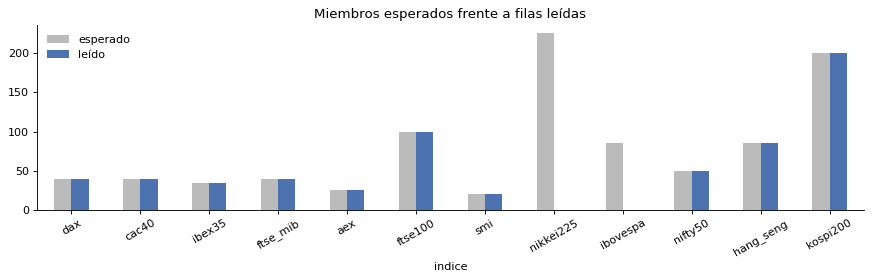

In [8]:
fi = json.loads((resultados_dir('mercados_series') / 'fichas' / 'indices_constituyentes.json').read_text(encoding='utf-8'))
med = pd.DataFrame(fi['mediciones']['indices'])
ax = med.set_index('indice')[['esperado', 'n_filas']].plot.bar(figsize=(11, 3.6), rot=30, color=['#BBBBBB', '#4C72B0'])
ax.set_title('Miembros esperados frente a filas leídas'); ax.legend(['esperado', 'leído'], frameon=False); plt.tight_layout(); plt.show()

## Conclusiones

- El universo tiene unos 200 instrumentos válidos (ids únicos, mercados conocidos, ISIN con dígito de
  control correcto, referencias cruzadas resueltas). El dígito de control descartó 5 ISIN de EE. UU.; XLI se
  recuperó de la ficha del emisor y CPER, BITO, VIXY y VBMFX siguen null (son señal, no se invierten).
- Todos los UCITS consultados tienen fecha de lanzamiento verificada en justETF; la consulta destapó dos ISIN
  intercambiados (consumo discrecional/básico) y un ISIN equivocado (agregado de EE. UU.: IUAA.L es
  IE00B44CGS96, verificado). AIGA.L tiene ISIN verificado pero Yahoo no da su historia; NGAS.L sigue sin ISIN.
- El `inicio_esperado` de los ETF de EE. UU. es el primer día con datos en Yahoo (medido): cinco difieren del
  lanzamiento anotado antes en días o semanas (VTI, EFA, EZU, EDV, BWX) y BITO en uno.
- La historia previa al UCITS depende del proxy de EE. UU.: el empalme se declara instrumento a instrumento.
- El S&P 500 es point-in-time desde 1996; el resto de índices, solo fotos actuales.